1. Cargando datos desde archivo local...
   Datos cargados: 1000 registros.
   Datos divididos y escalados correctamente.

2. Iniciando el Torneo de Algoritmos...
MODELO          | ACCURACY   | ESTABILIDAD (STD)
--------------------------------------------------
Logistica       | 0.9714     | 0.0181
LDA             | 0.9671     | 0.0144
Arbol           | 0.9414     | 0.0259
Random Forest   | 0.9671     | 0.0144
SVM             | 0.9629     | 0.0194


C:\Users\Rafael\AppData\Local\Temp\ipykernel_11564\3552665531.py:65: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(results, labels=names)


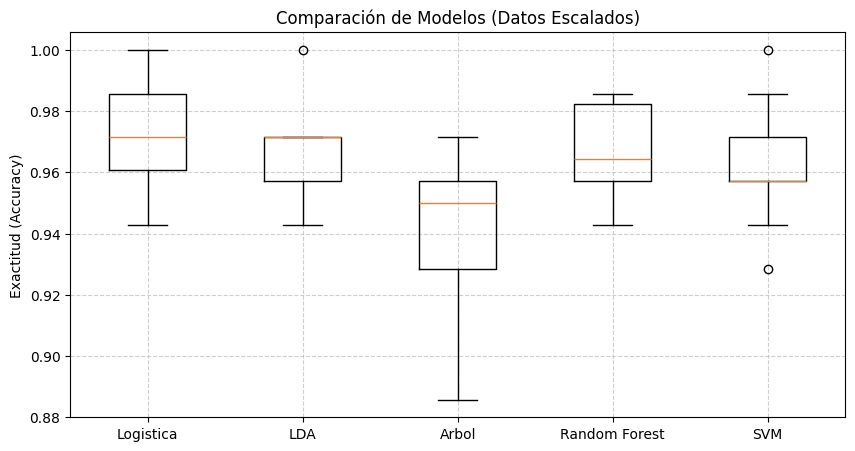


3. Optimizando Random Forest con Grid Search...
   Mejor Configuración: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 100}
   Accuracy en Validación: 96.14%

4. Evaluación Final (Test Set)...
   ACCURACY FINAL: 95.33%

--- Matriz de Confusión Final ---


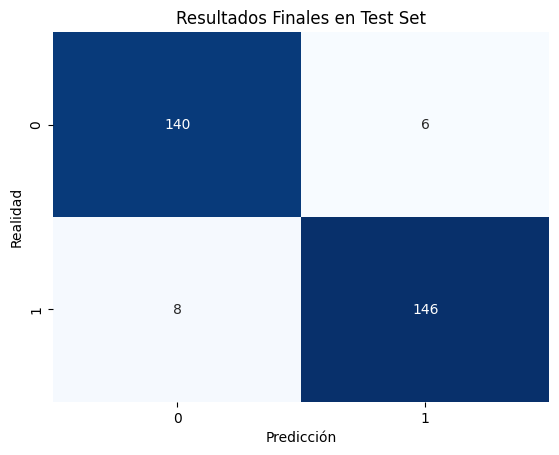


--- Reporte de Clasificación ---
              precision    recall  f1-score   support

           0       0.95      0.96      0.95       146
           1       0.96      0.95      0.95       154

    accuracy                           0.95       300
   macro avg       0.95      0.95      0.95       300
weighted avg       0.95      0.95      0.95       300



In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# --- PASO 1: CARGA DE DATOS LOCAL ---
print("1. Cargando datos desde archivo local...")
ad_data = pd.read_csv("../datasets/advertising.xls")

# Seleccionamos variables numéricas (Features) y el objetivo (Target)
features = ['Daily Time Spent on Site', 'Age', 'Area Income', 'Daily Internet Usage', 'Male']
X = ad_data[features]
y = ad_data['Clicked on Ad']

print(f"   Datos cargados: {X.shape[0]} registros.")

# --- PASO 2: SPLIT + ESCALADO ---
# Dividimos: 70% para Entrenar/Validar, 30% para el Examen Final (Test)
X_train_raw, X_test_raw, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Escalamos los datos (Vital para que SVM y Logística funcionen bien)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw)
X_test = scaler.transform(X_test_raw) # ¡Importante! Usar la misma regla de escala

print("   Datos divididos y escalados correctamente.")

# --- PASO 3: EL TORNEO DE MODELOS (Validación Cruzada) ---
print("\n2. Iniciando el Torneo de Algoritmos...")

# Definimos los competidores
modelos = []
modelos.append(('Logistica', LogisticRegression()))
modelos.append(('LDA', LinearDiscriminantAnalysis()))
modelos.append(('Arbol', DecisionTreeClassifier(random_state=42)))
modelos.append(('Random Forest', RandomForestClassifier(n_estimators=100, random_state=42)))
modelos.append(('SVM', SVC())) 

results = []
names = []

print(f"{'MODELO':<15} | {'ACCURACY':<10} | {'ESTABILIDAD (STD)'}")
print("-" * 50)

for name, model in modelos:
    # StratifiedKFold mantiene la proporción de clicks/no clicks en cada vuelta
    kfold = StratifiedKFold(n_splits=10, random_state=42, shuffle=True)
    cv_results = cross_val_score(model, X_train, y_train, cv=kfold, scoring='accuracy')
    results.append(cv_results)
    names.append(name)
    print(f"{name:<15} | {cv_results.mean():.4f}     | {cv_results.std():.4f}")

# Gráfico del Torneo
plt.figure(figsize=(10, 5))
plt.boxplot(results, labels=names)
plt.title('Comparación de Modelos (Datos Escalados)')
plt.ylabel('Exactitud (Accuracy)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# --- PASO 4: OPTIMIZACIÓN (Hyperparameter Tuning) ---
# Vamos a tunear Random Forest (suele ser el más robusto)
print("\n3. Optimizando Random Forest con Grid Search...")

param_grid = {
    'n_estimators': [50, 100, 200],     # Número de árboles
    'max_depth': [None, 10, 20],        # Profundidad máxima
    'min_samples_split': [2, 5]         # Mínimo de datos para dividir
}

grid = GridSearchCV(RandomForestClassifier(random_state=42), param_grid, cv=5, scoring='accuracy')
grid.fit(X_train, y_train)

print(f"   Mejor Configuración: {grid.best_params_}")
print(f"   Accuracy en Validación: {grid.best_score_:.2%}")

# --- PASO 5: EL EXAMEN FINAL (TEST SET) ---
print("\n4. Evaluación Final (Test Set)...")
best_model = grid.best_estimator_
y_pred = best_model.predict(X_test)

acc_final = accuracy_score(y_test, y_pred)
print(f"   ACCURACY FINAL: {acc_final:.2%}")

print("\n--- Matriz de Confusión Final ---")
# Visualizar la matriz
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.xlabel('Predicción')
plt.ylabel('Realidad')
plt.title('Resultados Finales en Test Set')
plt.show()

# Reporte detallado
print("\n--- Reporte de Clasificación ---")
print(classification_report(y_test, y_pred))


3. Optimizando Regresión Logística con Grid Search...
   Mejor Configuración: {'C': 0.1, 'penalty': 'l2', 'solver': 'lbfgs'}
   Accuracy en Validación: 97.14%

4. Evaluación Final (Test Set)...
   ACCURACY FINAL: 96.00%

--- Matriz de Confusión Final ---


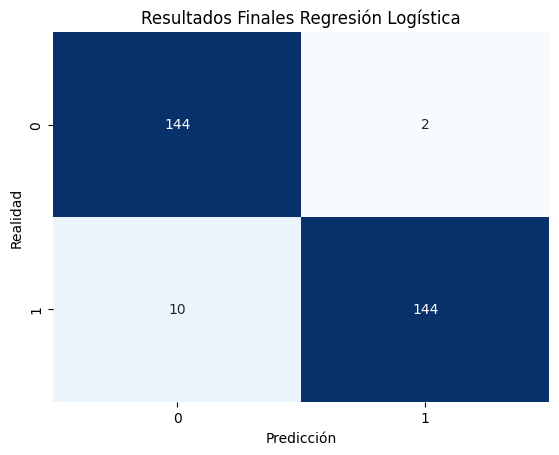


--- Reporte de Clasificación ---
              precision    recall  f1-score   support

           0       0.94      0.99      0.96       146
           1       0.99      0.94      0.96       154

    accuracy                           0.96       300
   macro avg       0.96      0.96      0.96       300
weighted avg       0.96      0.96      0.96       300



In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# --- PASO 4: OPTIMIZACIÓN (Hyperparameter Tuning) ---
print("\n3. Optimizando Regresión Logística con Grid Search...")

# Definimos los parámetros CORRECTOS para Logística
param_grid = {
    'C': [0.01, 0.1, 1, 10, 100],      # Inverso de la regularización (la perilla más importante)
    'solver': ['liblinear', 'lbfgs'],  # Algoritmos para encontrar el mínimo
    'penalty': ['l2']                  # Tipo de castigo (l2 es el estándar)
}

# Instanciamos GridSearchCV con LogisticRegression
# max_iter=1000 es para asegurar que converja sin warnings
grid = GridSearchCV(LogisticRegression(max_iter=1000), param_grid, cv=5, scoring='accuracy')

# Entrenamos con los datos ESCALADOS (X_train viene del paso anterior)
grid.fit(X_train, y_train)

print(f"   Mejor Configuración: {grid.best_params_}")
print(f"   Accuracy en Validación: {grid.best_score_:.2%}")

# --- PASO 5: EL EXAMEN FINAL (TEST SET) ---
print("\n4. Evaluación Final (Test Set)...")
best_model = grid.best_estimator_
y_pred = best_model.predict(X_test)

acc_final = accuracy_score(y_test, y_pred)
print(f"   ACCURACY FINAL: {acc_final:.2%}")

print("\n--- Matriz de Confusión Final ---")
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.xlabel('Predicción')
plt.ylabel('Realidad')
plt.title('Resultados Finales Regresión Logística')
plt.show()

# Reporte detallado
print("\n--- Reporte de Clasificación ---")
print(classification_report(y_test, y_pred))